# 6. 에이전트 평가와 개선

1~5번 노트북에서 구축한 에이전트는 몇 가지 예시 질문에는 자연스럽게 답합니다. 하지만 실제 업무 환경에 배포하려면 **어떤 유형의 질문에서 오답이 나거나 불필요한 도구 호출이 반복되는지 숫자로 확인하고, 모델이 아닌 시스템 구성요소(도구 반환 형식 · 인덱스 · 시맨틱 레이어 · 프롬프트) 중 어디를 고쳐야 하는지 찾아내는 과정**이 필요합니다.

이번 노트북에서는 **시드(Seed) 기반 평가 데이터셋 생성과 검수**, **기본 메트릭과 커스텀 메트릭을 조합한 벤치마크 구성**, **실패 원인 진단 및 개선 전후 비교(`compare_table`)**, 그리고 **실행 중 실시간 검증과 사람 승인(`Human-in-the-Loop`)** 까지 순서대로 실습합니다.

---

### 학습 목표
1. 오프라인 평가 기반 시스템 개선과 실행 중 실시간 개입의 차이를 구분하고, 정량 채점에서 원인 진단·개선·재검증으로 이어지는 흐름을 이해합니다.
2. 평가할 주제와 시나리오를 담은 시드(Seed)로부터 평가 문항 초안을 생성하고 판사 모델로 자동 검수하는 방법을 익힙니다.
3. 커스텀 메트릭(`Faithfulness` 2단계 검증, 출처 표기 검사)을 직접 구현하고, 기본 제공 메트릭과 리스트로 묶어 통합 평가 테이블을 산출합니다.
4. 도구 호출 궤적에서 과잉 탐색(`neg-01`)의 원인을 찾아 도구 반환 형식을 개선(`agent_v2`)한 뒤 전체 문항 재평가로 기존 문항의 점수 하락(회귀, Regression)이 없는지 확인하고, 운영 DB 조회 앞의 사람 승인 게이트(`HITL`)를 실습합니다.

### 학습 목차

| 파트 | 주제 | 핵심 내용 |
|:---:|:---|:---|
| **Step 0** | 환경 세팅 | 프로젝트 루트, 에이전트 모델(`gemini-3.8-flash`), 채점용 판사 모델(`gpt-5.4-mini`) 초기화 |
| **Part 1** | 평가가 필요한 이유와 개선 구조 | 오프라인 시스템 개선 vs 실행 중 개입, 사내 데이터 연결 3계층과 원인 진단 기준 |
| **Part 2** | 평가 데이터셋 구성과 시드 기반 생성 | 12문항 벤치마크 구조 살펴보기, 시드(`EvalSeed`) 기반 문항 생성·검수 모듈 활용 |
| **Part 3** | 커스텀 메트릭 구현과 벤치마크 조합 | `Faithfulness` 2단계 체인 및 출처 표기 함수 작성, `EvalMetric` 리스트 조합 |
| **Part 4** | 베이스라인 벤치마크 실행 | 12문항 통합 채점(`results_table`), 기준 미달 진단 표 및 호출 비용 산점도 분석 |
| **Part 5** | 원인 진단과 도구 반환 형식 개선 | `neg-01` 호출 궤적 분석 → `search_company_policy_v2` 적용 → `compare_table` 전후 비교 및 회귀 검증 |
| **Part 6** | 실행 중 개입과 운영 로그 피드백 루프 | 응답 확정 전 크로스체크(`after_agent`), ERP 조회 승인 게이트(`HITL`), 운영 로그 기반 평가셋 확장 |
| **Part 7** | 정리 | 전체 평가·개선 흐름 요약 및 심화 실습 과제 |

## Step 0. 환경 세팅

프로젝트 루트 경로를 자동 감지하여 `sys.path`에 등록하고 환경변수(`.env`)를 불러옵니다.
채점 시 같은 모델이 자기 답변을 후하게 평가하는 편향을 줄이기 위해, **평가 대상 에이전트(`gemini-3.8-flash`)** 와 **채점용 판사 모델(`gpt-5.4-mini`)** 은 서로 다른 계열의 모델로 초기화합니다.

In [1]:
import os
import sys
import warnings
import nest_asyncio
from dotenv import load_dotenv

warnings.filterwarnings("ignore", message=".*IProgress not found.*")

# 1. 프로젝트 루트 경로 자동 탐색 (app/ 폴더가 있는 위치)
project_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(project_root, "app")):
        break
    project_root = os.path.dirname(project_root)

os.chdir(project_root)
if project_root not in sys.path:
    sys.path.insert(0, project_root)

# 2. 환경변수 및 노트북 비동기 루프 설정
load_dotenv(os.path.join(project_root, ".env"), override=True)
nest_asyncio.apply()
print(f"Working Directory: {os.getcwd()}")

# 3. 에이전트용 모델과 채점용 판사 모델(타 계열) 초기화
from app.utils import init_chat_model, normalize_content
from app.eval import JUDGE_MODEL

llm = init_chat_model(model="gemini-3.8-flash", temperature=0.0)    # 평가 대상 에이전트 모델
judge_llm = init_chat_model(model=JUDGE_MODEL, temperature=0.0)      # 채점 전용 판사 모델 (gpt-5.4-mini)
print(f"Agent LLM: gemini-3.8-flash | Judge LLM: {JUDGE_MODEL}")

Working Directory: /mnt/c/Users/hyoun/Desktop/working_project/working_on_dir/Agentic_RAG/instructor


Agent LLM: gemini-3.8-flash | Judge LLM: gpt-5.4-mini


---
## Part 1. 왜 평가가 필요한가: 사내 데이터 연결 구조와 개선 흐름

### 1.1 눈으로 확인하는 데모의 한계와 두 가지 품질 개선 경로

에이전트에 질문 두세 개를 직접 입력해 보는 것만으로는 현장에서 발생하는 문제를 미리 알아차리기 어렵습니다. 특히 도구를 여러 개 쓰는 에이전트에서는 다음 두 가지 문제가 자주 숨어 있습니다.

- **조용한 오답**: 예를 들어 AWS 백서에서 *"성능 효율성 영역의 설계 원칙"*을 물었는데 검색 도구가 *"비용 최적화 영역의 설계 원칙"* 청크를 가져오면, 모델은 검색된 문서를 바탕으로 매끄럽게 요약해 그럴듯한 오답을 내놓습니다.
- **과잉 탐색으로 인한 지연과 비용**: 사내 규정에 없는 *"우주항공 특별 연구 상여금"*을 물었을 때 최종 답변은 *"확인되지 않는다"*로 맞히더라도, 그 결론을 내리기 전까지 규정·ERP·지식 그래프 도구를 8~10번씩 연쇄 호출하며 1분 넘게 시간을 쓰기도 합니다.

이처럼 숨어 있는 결함을 다루는 방법은 크게 **오프라인 평가로 시스템 자체를 고치는 경로**와 **실행 도중에 개입하는 경로**로 나뉩니다.

| 구분 | 오프라인 평가 기반 시스템 개선 | 실행 중 실시간 개입 (자가 교정 · 사람 승인) |
|:---|:---|:---|
| **개선 주체** | 엔지니어가 평가 결과 표와 도구 호출 기록을 분석해 수정 | 미들웨어나 담당자가 에이전트 실행 도중에 개입 |
| **수정 대상** | 도구 반환 형식, 검색 인덱스, 시맨틱 레이어, 시스템 프롬프트 | 해당 요청 단건의 답변 재작성 또는 도구 실행 승인·거절 |
| **비용 특성** | 개발·배포 점검 시점에만 평가 비용 발생 | 매 사용자 요청마다 추가 지연 시간과 토큰 비용 발생 |
| **지속 효과** | 한 번 고치면 이후 들어오는 모든 유사 질문에 일관되게 적용 | 시스템 결함이 그대로면 다음 요청에서도 같은 재작업 반복 |
| **다루는 위치** | **Part 2 ~ Part 5** (데이터셋 → 채점 → 진단 → 개선 및 재검증) | **Part 6** (응답 직전 크로스체크, ERP 조회 승인 게이트) |

검색어를 바꿔 다시 검색하는 수준의 보완은 모델이 기본 ReAct 루프 안에서 스스로 수행합니다. 따라서 엔지니어가 집중해야 할 일은 **에이전트가 스스로 고칠 수 없는 도구 인터페이스나 데이터 계층의 문제를 평가로 찾아내 개선하는 것**입니다.

```mermaid
%%{init: {'flowchart': {'htmlLabels': false, 'padding': 18, 'nodeSpacing': 32, 'rankSpacing': 46}}}%%
flowchart LR
    G["1. 평가 데이터셋
(유형별 질문 · 정답 · 도구)"] --> R["2. 에이전트 실행
(답변 + 호출 궤적 수집)"]
    R --> S["3. 정량 채점
(기본 + 커스텀 메트릭)"]
    S --> D["4. 원인 계층 진단
(도구 · 인덱스 · 프롬프트)"]
    D --> F["5. 구성요소 개선
(반환 형식 · 시맨틱 레이어)"]
    F --> RE(["6. 전체 문항 재평가 (회귀 여부 확인)"])
    RE --> G
```

### 1.2 사내 데이터 연결 3계층 구조와 원인 진단 기준

오답이 나올 때마다 시스템 프롬프트에 예외 지침을 한 줄씩 덧붙이는 방식은 금방 한계에 부딪힙니다. 프롬프트가 길어질수록 지침끼리 충돌하기 쉽고, 검색 청크에 문맥이 빠졌거나 도구가 모호한 결과를 돌려주는 근본 원인은 해결되지 않기 때문입니다.

우리가 1~5번 노트북에서 만든 시스템은 아래 그림처럼 **① 사내 원천 데이터 → ② 시맨틱·인덱스 계층 → ③ 에이전트 도구 인터페이스**의 3계층으로 구성되어 있습니다. 평가 점수가 낮게 나오면 어느 계층에서 정보가 어긋났는지 먼저 짚어내야 정확한 위치를 고칠 수 있습니다.

```mermaid
%%{init: {'flowchart': {'htmlLabels': false, 'padding': 18, 'nodeSpacing': 32, 'rankSpacing': 52}}}%%
flowchart LR
    subgraph L1["1계층: 사내 원천 데이터"]
        S1["사내 규정 및 백서
(Markdown / PDF)"]
        S2["사내 운영 데이터베이스
(ERP SQLite 7개 테이블)"]
        S3["조직도 · 결재선 · 과제
(다중 관계 문서)"]
    end

    subgraph L2["2계층: 시맨틱 · 인덱스 계층"]
        M1["문맥 헤더(목차·경로) 결합
+ 사내 약어 사전 정규화"]
        M2["시맨틱 레이어(업무 지표 공식)
+ 스키마 링킹 · 셀 값 연결"]
        M3["엔티티 · 관계 지식 그래프
+ 커뮤니티 요약 리포트"]
    end

    subgraph L3["3계층: 에이전트 도구 인터페이스"]
        T1["문서 검색 도구 2종
(출처 경로 + 미존재 신호)"]
        T2["ERP 조회 도구
(읽기 전용 검증 + 되묻기)"]
        T3["그래프 탐색 도구 5종
(엔티티 → 이웃 → 원문)"]
    end

    S1 --> M1 --> T1
    S2 --> M2 --> T2
    S3 --> M3 --> T3
```

| 점검 계층 | 주로 발생하는 문제 예시 | 이 프로젝트의 관련 구현 위치 |
|:---|:---|:---|
| **2계층: 시맨틱 · 인덱스** | 표 제목이 잘려 어느 직급 기준인지 알 수 없음, `'실집행액'` 집계 시 `'결재대기'`까지 잘못 합산함 | `HybridRetriever` 문맥 헤더, `DomainDictionary`, `semantic_layer.yaml` |
| **3계층: 도구 인터페이스** | 도구 설명이 모호해 엉뚱한 도구를 고름, 관련 규정이 없는데도 무관한 상위 청크를 계속 반환함 | `app/agents/tool_rag_agent/tools.py`, `rag/sql/text2sql_agent.py` |
| **프롬프트 · 실행 제어** | 출처 조항을 답변에 적지 않음, 도구로부터 `'관련 조항 없음'`을 받고도 탐색을 멈추지 않음 | `app/agents/tool_rag_agent/prompt.py` |
| **평가 데이터셋 라벨** | 에이전트는 정상적인 대체 경로로 정답을 찾았는데 채점 기준표에 한 가지 도구만 적혀 있어 감점됨 | `data/eval/golden_eval_dataset.json` |

---
## Part 2. 평가 데이터셋 구성과 시드(Seed) 기반 생성

### 2.1 기본 평가 데이터셋(`golden_eval_dataset.json`) 살펴보기

평가에 앞서 우리가 채점할 대상 에이전트(`tool_rag_agent`)가 어떤 데이터와 도구를 다루는지 먼저 정리해 보겠습니다.

- **연결된 사내 데이터 4종과 도구 8개**:
  1. **사내 5대 공식 규정** (`search_company_policy`): 여비, 인사복무, 정보보안, 위임전결·예산, 클라우드·GPU 운영 지침
  2. **AWS 아키텍처 백서 4종** (`search_aws_guides`): 보안, 신뢰성, 성능 효율성, 비용 최적화 영문 백서
  3. **사내 ERP 데이터베이스** (`search_enterprise_erp`): 부서, 임직원, 프로젝트, 지출 전표 등 7개 SQLite 테이블을 자연어로 조회하는 Text2SQL 도구
  4. **전사 지식 그래프** (`graph_find_entities`, `graph_neighbors` 등 5종): 인물·부서·프로젝트 간의 보고선, 승인권자, 선행 과제 의존 관계 탐색

`data/eval/golden_eval_dataset.json` 파일에는 이 4가지 데이터 저장소에서 자주 발생하는 실수 유형을 고르게 담은 **12개 평가 문항**이 들어 있습니다. 각 문항은 최종 답변과 문제 해결 과정을 함께 채점하기 위해 두 가지 기준 라벨을 포함합니다.

- **`ground_truth` (기준 정답)**: 최종 답변에 꼭 들어가야 할 수치, 조항 번호, 결론을 적은 채점 기준입니다.
- **`target_tools` (기대 호출 도구)**: 해당 질문을 풀기 위해 사용해야 하는 도구 목록입니다.

> **참고 — 대체 가능한 도구의 `"A | B"` 표기 이유**  
> 예를 들어 `org-01`(*"김철수 수석이 총괄하는 프로젝트의 예산 최종 승인권자"*)에 필요한 프로젝트 담당자·예산 정보는 **지식 그래프**와 **ERP `projects` 테이블** 양쪽에 모두 들어 있습니다. 만약 정답 도구를 지식 그래프 하나로만 고정해 두면, 에이전트가 ERP를 조회해 정확한 답을 내더라도 '도구 선택 오류'로 감점됩니다. 이처럼 정상적인 풀이 경로가 여럿인 문항은 `"graph_* ... | search_enterprise_erp"`처럼 `|`로 묶어 두어 어느 쪽을 쓰든 인정합니다.

In [2]:
import pandas as pd
from IPython.display import display
from app.eval import load_golden

golden = load_golden()
golden_df = pd.DataFrame(golden)[["id", "category", "question", "ground_truth", "target_tools"]]
golden_df.columns = ["문항 ID", "유형", "질문", "기준 정답 (ground_truth)", "기대 호출 도구 (target_tools)"]
display(golden_df.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}).hide(axis="index"))

문항 ID,유형,질문,기준 정답 (ground_truth),기대 호출 도구 (target_tools)
pol-01,단일 규정,팀원이 당일 출장을 가면 일비와 식비는 얼마를 받나요?,"국내 여비 및 교통비 지급 규정 제15조 제2항에 따라 당일 출장 시 일비는 기준액의 50%, 식비는 1식(12,000원)을 지급한다. 팀원(선임/전임)의 일비 기준액은 25,000원이므로 일비 12,500원과 식비 12,000원을 받는다.",['search_company_policy']
pol-02,약어 + 복수 조항,"클운팀 직원이 출장을 가면 결재는 누가 최종 승인하고, 정산은 언제까지 해야 하나요?",제21조에 따라 클라우드운영팀(클운팀)은 팀원 출장 시 팀장 승인 후 클라우드사업본부장이 전결한다. 제20조에 따라 출장 종료일로부터 7영업일 이내에 사내 ERP의 '여비교통비 정산 신청' 메뉴로 영수증을 첨부해 결재를 상신해야 한다.,['search_company_policy']
pol-03,표 데이터 + 계산,서울 출장 시 팀장과 팀원의 1박 숙박비 한도 차이는 얼마인가요?,"제14조 표에 따라 서울 및 수도권 1박 숙박비 상한은 팀장(수석/책임) 130,000원, 팀원(선임/전임) 100,000원이므로 차이는 30,000원이다.",['search_company_policy']
sec-01,복수 조항,"고객사 납품용 소스코드를 사외로 반출하려면 어떤 승인을 받아야 하고, 위반하면 어떻게 되나요?","정보보안 관리 지침 제14조에 따라 DLP 결재 시스템으로 사전 신청하고 1차 소속 팀장, 2차 CISO(정보보안책임자)의 승인을 받아야 한다. 제15조에 따라 위반으로 정보가 유출되면 인사위원회에 회부되어 사규 제45조에 따라 경고, 감봉, 정직 또는 징계해고에 처할 수 있고 민형사상 손해배상 책임을 질 수 있다.",['search_company_policy']
org-01,다중 홉 관계,김철수 수석이 총괄하는 프로젝트의 예산을 최종 승인하는 사람은 누구인가요?,"김철수 수석(클라우드운영팀 팀장)은 P-01 클라우드 네이티브 마이그레이션의 총괄 PM이다. 예산은 3억 5,000만원으로 5,000만원 이상 5억원 미만 구간이므로 소속 본부장이 최종 승인하며, 승인권자는 클라우드사업본부장 박영희 전무다.",['graph_* 탐색 도구(graph_find_entities → graph_neighbors) | search_enterprise_erp']
org-02,다중 홉 관계,P-02 Agentic RAG 플랫폼 프로젝트의 일정에 영향을 줄 수 있는 의존 관계는 무엇인가요?,"P-02(엔터프라이즈 Agentic RAG 플랫폼 구축, 총괄 PM 홍팀장)의 일정은 선행 프로젝트 네 개에 걸려 있다. ① P-01 클라우드 네이티브 마이그레이션의 하이브리드 K8s 인프라 구축 완료가 선행 필수이고, ② P-05 멀티클라우드 GPU 추론 클러스터 고도화의 vLLM 서빙 노드 할당이 선행 필수이며, ③ P-03 차세대 AI 데이터 거버넌스의 Query-Time ACL 필터와 ④ P-04 금융권 생성형 AI 보안 가드레일의 입출력 마스킹 모듈을 출시 전에 통합해야 한다. 또한 클라우드운영팀에서 최책임 책임엔지니어를 파견받아 협업하고 있어 인력 의존도 있다. (P-06과의 관계, 정보보안팀 레드팀 감사 등을 추가로 언급하는 것은 무방하다.)",['graph_* 탐색 도구(graph_find_entities → graph_neighbors) | search_enterprise_erp']
aws-01,동일 소스 다회 검색,AWS Well-Architected 프레임워크에서 성능 효율성 영역과 비용 최적화 영역의 설계 원칙을 비교해줘.,"성능 효율성(Performance Efficiency) 백서의 설계 원칙은 ① 고급 기술의 대중화(Democratize advanced technologies), ② 몇 분 만에 글로벌 배포(Go global in minutes), ③ 서버리스 아키텍처 사용(Use serverless architectures), ④ 더 자주 실험(Experiment more often), ⑤ 기계적 공감 고려(Consider mechanical sympathy)의 5가지다. 비용 최적화(Cost Optimization) 백서의 설계 원칙은 ① 클라우드 재무 관리 구현(Implement cloud financial management), ② 소비 모델 채택(Adopt a consumption model), ③ 전체 효율성 측정(Measure overall efficiency), ④ 차별화되지 않는 과중한 작업에 대한 지출 중단(Stop spending money on undifferentiated heavy lifting), ⑤ 지출 분석 및 귀속(Analyze and attribute expenditure)의 5가지다. 두 영역의 원칙을 서로 바꾸어 답하거나 다른 영역(보안·신뢰성)의 원칙을 섞으면 오답이다.",['search_aws_guides']
erp-01,정형 데이터 집계,"승인완료된 지출 기준으로 예산 집행률이 80%를 넘은 전략 프로젝트는 어디이고, 집행률은 각각 몇 %인가요?","ERP의 프로젝트 승인 예산 대비 '승인완료' 지출 전표 합계로 계산하면 두 프로젝트가 80%를 넘는다. P-02 엔터프라이즈 Agentic RAG 플랫폼 구축은 승인 예산 480,000,000원 중 412,800,000원을 집행해 86.0%이고, P-05 멀티클라우드 GPU 추론 클러스터 고도화는 620,000,000원 중 527,000,000원을 집행해 85.0%다.",['search_enterprise_erp']
mix-01,이종 소스 결합 (그래프 + 규정),AgenticAI팀 홍팀장이 대구로 2박 3일 출장을 가면 숙박비 한도와 일비 총액은 얼마인가요?,"홍팀장은 AgenticAI팀 팀장(수석)으로 팀장(수석/책임) 기준이 적용된다. 대구는 광역시이므로 제14조에 따라 1박 숙박비 상한 100,000원(2박 최대 200,000원), 제15조에 따라 일비 1일 30,000원 × 3일 = 90,000원이다.","['graph_* 탐색 도구(graph_find_entities → graph_neighbors) | search_enterprise_erp', 'search_company_policy']"
cross-01,이종 소스 결합 (규정 + ERP),"국내 여비 규정의 숙박비 한도를 기준으로, ERP에서 결재대기 중인 국내출장 품의 가운데 1박당 숙박비 한도를 초과한 건을 모두 찾아줘.","국내 여비 및 교통비 지급 규정 제14조의 1박 상한은 팀장(수석/책임) 서울 130,000원·광역시 100,000원, 팀원(선임/전임) 서울 100,000원·광역시 80,000원이다. 이 기준으로 결재대기 국내출장 품의를 대조하면 3건이 초과한다. ① TX-2026-0131 이선임(선임): 서울 1박 150,000원 청구, 상한 100,000원 대비 50,000원 초과. ② TX-2026-0132 윤에이전트(책임): 부산 2박 280,000원(1박 140,000원) 청구, 상한 100,000원 대비 1박당 40,000원(총 80,000원) 초과. ③ TX-2026-0133 장LLM(선임): 대전 1박 120,000원 청구, 상한 80,000원 대비 40,000원 초과. 나머지 결재대기 국내출장 품의(TX-2026-0119, 0121, 0125)는 한도 이내다.","['search_company_policy', 'search_enterprise_erp']"


위 12개 문항이 각각 어떤 상황을 점검하기 위해 배치되었는지 요약하면 다음과 같습니다.

| 평가 유형 | 해당 문항 | 점검하려는 주요 상황 |
|:---|:---|:---|
| 단일·복수 조항 및 표 계산 | `pol-01~03`, `sec-01` | 관련 조항 검색 정확도, 마크다운 표의 직급·지역별 금액 비교 및 합산 |
| 사내 약어 · 미정의 호칭 | `pol-02`, `term-01` | 부서 약칭(`클운팀`) 인식, 사규에 없는 직급 호칭(`과장급`) 질문 시 추측 방지 |
| 다단계 관계 추적 | `org-01`, `org-02` | 담당 과제 확인 후 예산 구간별 전결권자나 선행 과제 의존 관계를 이어서 탐색 |
| 동일 저장소 다중 검색 | `aws-01` | 영문 백서 두 권에서 동명 섹션(`Design principles`)을 혼동하지 않고 각각 검색 |
| 정형 데이터 조건 집계 | `erp-01` | 시맨틱 레이어의 공식(`승인완료` 전표만 합산)에 맞춘 예산 집행률 계산 |
| 이종 데이터 결합 | `mix-01`, `cross-01` | 앞 도구에서 확인한 직급이나 규정 상한액을 다음 도구 조회 조건(`context`)으로 전달 |
| 존재하지 않는 정보 | `neg-01` | 사내에 없는 제도를 지어내지 않고, 불필요한 반복 호출 없이 탐색을 마무리하는지 확인 |

### 2.2 시드(Seed) 기반 평가 데이터셋 생성과 자동 검수

실무에서 평가 데이터셋을 만들고 넓혀 가는 시점은 크게 **서비스 배포 전**과 **서비스 운영 중** 두 단계로 나뉩니다.

- **서비스 배포 전 (초기 평가셋 구축)**: 아직 실제 사용자 질문 기록이 없으므로 사내 규정 문서와 DB 스키마를 바탕으로 예상 질문과 정답을 만듭니다. 이때 문서 전체를 LLM에 넣고 *"문제 10개 만들어줘"*라고만 지시하면 원문 문장을 그대로 옮긴 단답형 문제나 *"위 표에 따르면..."*처럼 원문을 보지 않고는 답할 수 없는 불완전한 질문이 생성되기 쉽습니다.
- **서비스 운영 중 (실패 사례 추가)**: 배포 이후에는 트레이스 로그(LangSmith, Langfuse 등)에 기록된 사용자 부정 피드백이나 사람 승인 거절·수정 사례를 추려 정답만 다듬어 평가셋에 추가합니다.

초기 평가셋을 실용적으로 만들려면 엔지니어가 먼저 **시드(Seed: 평가할 유형, 주제, 구체적인 질문 시나리오, 참조할 원천 문서, 기대 도구)** 를 명확히 정의해 주고, 그 시드로부터 생성된 문항을 다른 계열의 판사 모델로 자동 검수하는 방식이 효과적입니다.

```mermaid
%%{init: {'flowchart': {'htmlLabels': false, 'padding': 18, 'nodeSpacing': 32, 'rankSpacing': 48}}}%%
flowchart LR
    S["1. 시드(Seed) 정의
(주제 · 시나리오 · 참조 문서)"] --> G["2. 문항 초안 생성
(질문 · 기준 정답 작성)"]
    G --> V{"3. 판사 모델 검수
(근거 · 독립성 · 명확성)"}
    V --> H["4. 검수 통과: 담당자 확인
(도메인 기준 점검)"]
    V --> X["검수 미달:
제외 또는 시드 보정"]
    H --> D["5. 평가 데이터셋에 추가
(golden_eval_dataset.json)"]
```

이 생성·검수 로직은 `app/eval/dataset_builder.py`에 모듈화되어 있습니다. 노트북에서는 생성하려는 평가 시나리오를 `EvalSeed` 리스트로 정의해 전달하기만 하면 됩니다.
- `generate_from_seeds(seeds, llm)`: 각 시드에 지정된 원천 문서 구간을 발췌해 시나리오 조건에 맞는 질문과 기준 정답 초안을 생성합니다.
- `verify_generated_cases(drafts, seeds, judge_llm)`: 다른 계열의 판사 모델이 **① 원문 수치·조항 일치 여부(`is_grounded`)**, **② 질문 단독 완결성(`is_standalone`)**, **③ 채점 기준의 명확성(`is_clear_rubric`)** 세 가지를 검사해 통과한 문항만 추려 줍니다.

In [3]:
from app.eval.dataset_builder import EvalSeed, generate_from_seeds, verify_generated_cases

# 1. 생성할 평가 문항의 시드(유형 · 주제 · 시나리오 지침 · 참조 문서 · 기대 도구)를 정의합니다.
seeds = [
    EvalSeed(
        id="syn-01",
        category="표 데이터 + 계산",
        topic="지방 숙박 출장 여비 합산",
        scenario="직급·광역시·숙박 일수 조건을 주어 숙박비 상한과 일비·식비를 표에서 찾아 합산해야 하는 질문",
        source_files=["data/policies/2026_국내여비교통비지급규정.md"],
        section_keyword="제14조",
        target_tools=["search_company_policy"],
    ),
    EvalSeed(
        id="syn-02",
        category="용어 불일치",
        topic="비공식 직급 호칭('차장급') 출장비 문의",
        scenario="사규 공식 직급(수석/책임/선임/전임)에 없는 '차장급'으로 질문하고, 정답에는 가능한 직급별 금액과 인사기획팀 확인 절차를 명시",
        source_files=["data/policies/2026_국내여비교통비지급규정.md"],
        section_keyword="제14조",
        target_tools=["search_company_policy"],
    ),
    EvalSeed(
        id="syn-03",
        category="이종 소스 결합 (규정 + ERP)",
        topic="여비 규정 상한액 기준 ERP 출장 전표 점검",
        scenario="여비 규정의 지역·직급별 숙박비 한도를 먼저 찾고 ERP 지출 전표(expense_transactions)와 대조해야 하는 질문",
        source_files=[
            "data/policies/2026_국내여비교통비지급규정.md",
            "data/enterprise_erp_sql/semantic_layer.yaml",
        ],
        section_keyword="제14조",
        target_tools=["search_company_policy", "search_enterprise_erp"],
    ),
    EvalSeed(
        id="syn-04",
        category="존재하지 않는 정보",
        topic="사규에 없는 출장 특별 수당 문의",
        scenario="출장·여비와 연관된 것처럼 보이지만 원천 규정에 실제로 없는 수당 제도를 묻고, 정답에는 규정 미존재를 안내하도록 작성",
        source_files=["data/policies/2026_국내여비교통비지급규정.md"],
        section_keyword="제14조",
        target_tools=["search_company_policy"],
    ),
]

# 2. 시드로부터 문항 초안 생성 후 판사 모델(judge_llm)로 자동 품질 검수
draft_cases = await generate_from_seeds(seeds, llm=llm)
verified_df, accepted_cases = await verify_generated_cases(draft_cases, seeds, judge_llm=judge_llm)

display(verified_df.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}).hide(axis="index"))
print(f"\n검수 통과: {len(accepted_cases)}/{len(draft_cases)}건 -> 담당자 확인 후 golden_eval_dataset.json 형식으로 바로 추가 가능")

문항 ID,유형,시드 주제,생성된 질문,기대 도구,검수 판정,검수 의견
syn-01,표 데이터 + 계산,지방 숙박 출장 여비 합산,"팀원(선임) 직급 직원이 광역시로 2박 3일간 국내 출장을 다녀올 경우, 지급 규정상 지원받을 수 있는 숙박비 최대 상한액과 일비 및 식비 정액 지급액의 총 합계 금액은 얼마인가요? (단, 식사는 별도로 제공되지 않았으며 예외 승인은 없는 것으로 가정함)",['search_company_policy'],통과,"숙박비·일비·식비의 직급/지역별 수치가 원천 문서와 정확히 일치하며, 2박 3일 기준으로 1일치 일비·식비를 3일로 계산한 합산도 맞습니다. 질문만으로 대상 직급, 지역, 숙박 일수, 식사 미제공 조건이 명확해 채점 기준도 모호하지 않습니다."
syn-02,용어 불일치,비공식 직급 호칭('차장급') 출장비 문의,외부 파견 인력인 차장급 직원이 서울로 1박 2일 국내 출장을 가게 되었습니다. 이 경우 1박당 숙박비 상한액과 1일당 일비 및 식비 지급 기준은 어떻게 되나요?,['search_company_policy'],통과,"원천 문서에 '차장'은 공식 직급이 아니므로 인사기획팀 매핑 확인 후 팀장/팀원 기준을 적용하라는 안내가 있으며, 서울 지역 1박 숙박비·1일 일비·식비 금액도 제14조/제15조 표와 정확히 일치합니다. 질문만으로도 대상(외부 파견 인력, 차장급)과 필요한 조건(국내, 서울, 1박 2일)이 명확하고, 정답 역시 가능한 직급별 금액과 확인 절차를 함께 제시해 채점 기준이 분명합니다."
syn-03,이종 소스 결합 (규정 + ERP),여비 규정 상한액 기준 ERP 출장 전표 점검,"선임 직급 팀원이 광역시 및 특례시 지역으로 국내 출장을 다녀온 뒤 숙박비를 정산하려고 합니다. 사내 국내여비교통비 지급 규정에 명시된 1박당 숙박비 상한액 기준은 얼마이며, ERP 지출 전표(expense_transactions)를 점검할 때 규정 위반(한도 초과) 여부를 판단하는 기준 금액과 사전 예외 승인 시 최대 인정 가능 금액을 각각 설명해 주세요.","['search_company_policy', 'search_enterprise_erp']",통과,"숙박비 한도 80,000원과 예외 승인 시 최대 104,000원(상한액의 30% 추가)은 원문 제14조와 정확히 일치합니다. 질문만으로도 직급(선임/전임)과 지역(광역시 및 특례시), 판단 기준(한도 초과 및 예외 승인 최대액)이 명확해 채점 기준도 모호하지 않습니다."
syn-04,존재하지 않는 정보,사규에 없는 출장 특별 수당 문의,"국내 또는 해외 출장 일정이 주말이나 공휴일에 걸쳐 진행되는 경우, 기본 일비와 식비 외에 추가로 신청하여 받을 수 있는 '주말 출장 특별 수당'의 지급 기준과 금액은 어떻게 되나요?",['search_company_policy'],통과,"원천 문서에는 국내·해외 출장의 숙박비, 일비·식비, 교통비, 해외 부대비용만 규정되어 있고, 주말/공휴일 출장 특별 수당 조항은 보이지 않습니다. 질문도 원문 없이 이해 가능하며, 정답은 규정 미존재를 명확히 안내해 채점 기준이 분명합니다."



검수 통과: 4/4건 -> 담당자 확인 후 golden_eval_dataset.json 형식으로 바로 추가 가능


---
## Part 3. 커스텀 메트릭 구현과 벤치마크 조합

### 3.1 기본 메트릭과 커스텀 메트릭: 어떻게 나누어 준비할까?

평가 벤치마크를 만들 때 모든 지표를 매번 처음부터 작성할 필요는 없습니다. 실무에서는 **미리 검증된 기본 메트릭**과 **우리 서비스의 규칙에 맞춘 커스텀 메트릭**을 조합해 하나의 평가 목록으로 묶어 사용합니다.

| 구분 | 예시 지표 | 측정 내용 | 구현 및 활용 방식 |
|:---|:---|:---|:---|
| **기본 제공 메트릭**<br/>(`app.eval.metrics`) | `answer_correctness` (정답 일치)<br/>`context_recall` (검색 재현)<br/>`tool_selection` (도구 선택)<br/>`step_economy` (호출 효율) | 기준 정답과의 사실 일치도, 필수 근거 검색 여부, 질문에 맞는 도구 선택 및 중복 호출 여부 | 도메인이 바뀌어도 채점 구조가 동일하므로 모듈에 준비된 지표를 그대로 임포트해 사용 |
| **커스텀 LLM 메트릭**<br/>(직접 정의) | `faithfulness_2step`<br/>(2단계 근거 충실도) | 답변의 세부 문장들이 검색된 문서 내용에만 근거하는지(환각 여부) 정밀 대조 | 단일 점수 프롬프트 대신 **문장 분해 → 문맥 대조** 2단계 체인으로 직접 작성 |
| **커스텀 코드 메트릭**<br/>(직접 정의) | `source_citation`<br/>(출처 식별자 표기) | 답변에 조항 번호(`제15조`), 전표 번호(`TX-...`), 과제 코드(`P-02`) 등 근거 출처가 명시되었는지 확인 | 정규표현식·조건문을 이용한 일반 Python 함수로 작성 (비용 0, 항상 동일한 결과 보장) |

> **커스텀 메트릭 작성 시 유의할 점**  
> 출처 표기 여부, 금지어 포함 여부, 호출 횟수 상한처럼 **코드로 판별할 수 있는 규칙은 일반 Python 함수로 작성**하는 것이 가장 빠르고 정확합니다. LLM 판사는 문장의 의미적 일치나 환각 검증처럼 규칙만으로 판단하기 어려운 항목에만 사용합니다.

이번 파트에서는 다음 세 단계를 순서대로 진행해 봅니다.
1. **커스텀 메트릭 직접 구현**: 2단계 근거 충실도(`score_faithfulness_2step`)와 출처 표기 검사(`score_source_citation`) 함수를 만들고 샘플 답변으로 동작을 확인합니다.
2. **메트릭 모듈화 및 리스트 조합**: 작성한 함수를 `EvalMetric`으로 감싸고, `app.eval.metrics`의 기본 메트릭들과 함께 하나의 `benchmark_metrics` 리스트로 묶습니다.
3. **통합 테이블 평가 (Part 4 연결)**: 조합한 리스트를 `evaluate_agent`에 전달해 모든 지표 점수를 한 테이블에서 나란히 확인합니다.

### 3.2 [실습 1] 커스텀 메트릭 직접 만들기

#### ① LLM 체인 기반 커스텀 메트릭: 2단계 근거 충실도 (`score_faithfulness_2step`)

*"다음 답변의 근거 충실도를 0.0~1.0 사이로 채점해줘"* 같은 단일 프롬프트는 실행할 때마다 점수가 흔들리고, 유창한 문장 사이에 섞인 작은 수치 왜곡을 놓치기 쉽습니다. 이를 막기 위해 다음 두 단계로 나누어 채점하는 함수를 작성합니다.

1. **1단계 — 단일 사실 문장 분해 (`ExtractedClaims`)**: 긴 답변에서 인사말을 제외하고 검증 가능한 짧은 사실 문장(`claims`) 목록으로 쪼갭니다. 이때 *"사내 규정에서 확인되지 않습니다"*처럼 없는 제도를 정당하게 안내한 답변(`is_abstention=True`)인지 함께 표시해, 검증할 사실 주장이 0개일 때 0점으로 잘못 계산되는 문제를 예방합니다.
2. **2단계 — 질문 제외 문맥 대조 (`ClaimVerdict`)**: 판사 모델에게 **사용자 질문은 빼고 검색된 문맥(`contexts`)과 분해된 주장(`claims`)만 전달**해 각 문장이 문맥으로 뒷받침되는지(`yes` / `no` / `idk`) 판정하게 합니다. 질문을 함께 보여주면 판사 모델이 검색 결과가 아닌 사전 지식으로 통과시키는 편향이 생길 수 있기 때문입니다. 최종 점수는 $\frac{\text{yes 개수}}{\text{yes 개수} + \text{no 개수}}$로 계산합니다.

In [4]:
from typing import Literal
from pydantic import BaseModel, Field
from langchain_core.prompts import ChatPromptTemplate


class ExtractedClaims(BaseModel):
    is_abstention: bool = Field(
        description="답변의 핵심 결론이 '문서/시스템에서 확인되지 않는다(정보 없음)'는 정당한 미존재 안내인지 여부"
    )
    claims: list[str] = Field(
        description="답변에서 추출한 대명사 해소된 단일 사실 주장 목록. 인사말·형식적 안내문은 제외"
    )


class ClaimVerdict(BaseModel):
    claim: str = Field(description="검증 대상 단일 사실 주장")
    evidence: str = Field(description="검색 문맥 내 관련 근거 요약 또는 불일치/부재 사유 (1문장)")
    verdict: Literal["yes", "no", "idk"] = Field(
        description="문맥으로 뒷받침되면 'yes', 문맥과 충돌하거나 문맥에 없는 수치·조건을 단정하면 'no', 단순 연결·미존재 안내라 참/거짓 판정이 불가하면 'idk'"
    )


class FaithfulnessReport(BaseModel):
    verdicts: list[ClaimVerdict]


CLAIM_EXTRACT_PROMPT = ChatPromptTemplate.from_messages([
    ("system",
     "주어진 [에이전트 답변]을 검증 가능한 단일 사실 주장 단위로 분해하세요.\n"
     "1. 각 문장은 독립적으로 뜻이 통하도록 대명사('동 규정', '해당 직급' 등)를 원래 명사로 풀어서 쓰세요.\n"
     "2. 복합문(A이고 B이다)은 단일 사실 단위로 쪼개고, 인사말·맺음말은 제외하세요.\n"
     "3. 답변의 결론이 '관련 규정이 확인되지 않는다'는 미존재 안내이고 지어낸 세부 기준이 없다면 is_abstention=True로 표시하세요."),
    ("human", "[에이전트 답변]\n{answer}"),
])

# 2단계 검증에는 사용자 질문(question)을 제외하고 검색된 문맥(contexts)과 주장(claims)만 전달합니다.
NLI_VERIFY_PROMPT = ChatPromptTemplate.from_messages([
    ("system",
     "당신은 사실 검증 평가자입니다. 오직 [검색된 문맥]만을 근거로 각 주장을 판정하세요.\n"
     "- 사전 지식이나 상식을 사용하지 마세요.\n"
     "- 'yes': 문맥에서 직접 확인되거나, 문맥의 수치로 정확히 계산된 결과이거나, 영문 원문을 한국어로 번역·요약한 사실\n"
     "- 'no': 문맥과 모순되거나, 문맥에 전혀 없는 수치·조항·예외 조건을 사실처럼 단정한 주장\n"
     "- 'idk': 문맥과 충돌하지 않는 일반적인 연결 문장이나 미존재 진술"),
    ("human", "[검색된 문맥]\n{contexts}\n\n[검증할 주장 목록]\n{claims}"),
])


async def score_faithfulness_2step(answer: str, contexts: list[str]) -> dict:
    extracted = await (CLAIM_EXTRACT_PROMPT | judge_llm.with_structured_output(ExtractedClaims)).ainvoke({"answer": answer})
    if extracted.is_abstention and not extracted.claims:
        return {"score": 1.0, "is_abstention": True, "verdicts": []}
    if not extracted.claims:
        return {"score": 0.0, "is_abstention": False, "verdicts": []}

    context_text = "\n---\n".join(contexts) if contexts else "[검색된 문맥 없음]"
    numbered = "\n".join(f"{i+1}. {c}" for i, c in enumerate(extracted.claims))
    report = await (NLI_VERIFY_PROMPT | judge_llm.with_structured_output(FaithfulnessReport)).ainvoke(
        {"contexts": context_text, "claims": numbered}
    )
    yes_cnt = sum(v.verdict == "yes" for v in report.verdicts)
    no_cnt = sum(v.verdict == "no" for v in report.verdicts)
    denom = yes_cnt + no_cnt
    score = 1.0 if (denom == 0 and extracted.is_abstention) else (yes_cnt / denom if denom else 0.0)
    return {"score": round(score, 2), "is_abstention": extracted.is_abstention, "verdicts": report.verdicts}


sample_ctx = [
    "[국내여비교통비지급규정 > 제15조(일비·식비)]:\n"
    "당일 출장 시 일비는 기준액(팀원 25,000원)의 50%인 12,500원, 식비는 1식(12,000원)을 지급한다."
]
samples = [
    ("정상 근거 답변", "제15조에 따라 팀원이 당일 출장을 가면 일비 12,500원(기준액 25,000원의 50%)과 식비 12,000원을 받습니다."),
    ("교묘한 환각 혼입", "제15조에 따라 팀원 당일 출장 시 일비 12,500원과 식비 12,000원을 받습니다. 단, 22시 이후 복귀 시 심야 교통비 30,000원이 추가 지급됩니다."),
    ("정당한 미존재 안내", "사내 규정을 확인했으나 요청하신 '우주항공 특별 연구 상여금' 제도는 확인되지 않습니다."),
]

for title, ans in samples:
    res = await score_faithfulness_2step(ans, sample_ctx)
    print(f"[{title}] Faithfulness = {res['score']:.2f} (미존재 응답 보호={res['is_abstention']})")
    for v in res["verdicts"]:
        print(f"   - [{v.verdict:<3}] {v.claim}  <- {v.evidence}")

[정상 근거 답변] Faithfulness = 1.00 (미존재 응답 보호=False)
   - [yes] 제15조에 따라 팀원이 당일 출장을 가면 일비는 12,500원이다.  <- 문맥에 “당일 출장 시 일비는 기준액(팀원 25,000원)의 50%인 12,500원”이라고 되어 있다.
   - [yes] 일비 12,500원은 기준액 25,000원의 50%이다.  <- 문맥에 “기준액(팀원 25,000원)의 50%인 12,500원”이라고 명시되어 있다.
   - [yes] 팀원이 당일 출장을 가면 식비는 12,000원이다.  <- 문맥에 “식비는 1식(12,000원)을 지급한다”라고 되어 있다.


[교묘한 환각 혼입] Faithfulness = 0.67 (미존재 응답 보호=False)
   - [yes] 제15조에 따라 팀원은 당일 출장 시 일비 12,500원을 받는다.  <- 문맥에 당일 출장 시 일비는 기준액(팀원 25,000원)의 50%인 12,500원이라고 되어 있다.
   - [yes] 제15조에 따라 팀원은 당일 출장 시 식비 12,000원을 받는다.  <- 문맥에 당일 출장 시 식비는 1식(12,000원)을 지급한다고 되어 있다.
   - [no ] 팀원은 22시 이후 복귀 시 심야 교통비 30,000원을 추가로 지급받는다.  <- 제시된 문맥에는 22시 이후 복귀나 심야 교통비 30,000원에 대한 내용이 없다.


[정당한 미존재 안내] Faithfulness = 1.00 (미존재 응답 보호=True)
   - [yes] 사내 규정에서 요청하신 '우주항공 특별 연구 상여금' 제도는 확인되지 않는다.  <- 제시된 문맥은 '국내여비교통비지급규정 > 제15조(일비·식비)'의 당일 출장 일비·식비 기준만 설명하며, '우주항공 특별 연구 상여금'에 대한 내용은 없다.


#### ② Python 코드 기반 커스텀 메트릭: 출처 식별자 표기 검사 (`score_source_citation`)

사내 업무용 에이전트는 사용자가 원문을 바로 대조할 수 있도록 조항 번호(`제15조`, `별표 1`), 전표 번호(`TX-2026-0131`), 과제 코드(`P-02`), 백서 명칭 등 근거 출처를 답변에 함께 적어야 합니다. 이러한 형식 준수 여부는 LLM을 부를 필요 없이 정규표현식 함수 하나로 즉시 채점할 수 있습니다. (단, 없는 제도를 묻는 질문에서 `'확인되지 않는다'`고 안내한 경우도 정상 응답으로 인정합니다.)

In [5]:
import re

CITATION_PATTERN = re.compile(r"(제\s*\d+\s*조|별표\s*\d+|TX-\d{4}-\d+|P-0\d|Well-Architected|백서)")
ABSTENTION_PATTERN = re.compile(r"(확인되지\s*않|존재하지\s*않|규정이\s*없)")


def score_source_citation(answer: str) -> dict:
    '''답변에 출처 식별자(조항·별표·전표·과제코드·백서명)가 포함되었거나 정당한 미존재 안내인지 검사합니다.'''
    refs = sorted(set(CITATION_PATTERN.findall(answer)))
    is_abstention = bool(ABSTENTION_PATTERN.search(answer))
    return {
        "score": 1.0 if (refs or is_abstention) else 0.0,
        "references": refs,
        "is_abstention": is_abstention,
    }


print("출처 표기 답변 :", score_source_citation("제15조에 따라 당일 출장 일비는 12,500원입니다."))
print("출처 누락 답변 :", score_source_citation("당일 출장 일비는 12,500원입니다."))
print("미존재 안내 답변:", score_source_citation("사내 규정에서 해당 상여금 제도는 확인되지 않습니다."))

출처 표기 답변 : {'score': 1.0, 'references': ['제15조'], 'is_abstention': False}
출처 누락 답변 : {'score': 0.0, 'references': [], 'is_abstention': False}
미존재 안내 답변: {'score': 1.0, 'references': [], 'is_abstention': True}


### 3.3 [실습 2] 기본 메트릭과 커스텀 메트릭을 리스트로 묶어 벤치마크 구성하기

이제 방금 작성한 커스텀 함수 2종(`score_faithfulness_2step`, `score_source_citation`)을 `app.eval.metrics`의 `EvalMetric`으로 감싸고, 미리 준비된 **기본 제공 메트릭 4종**과 함께 하나의 파이썬 리스트(`benchmark_metrics`)로 조합합니다.

- **`EvalMetric`의 자동 인자 연결**: 채점 함수가 동기 함수(`def`)이든 비동기 함수(`async def`)이든 상관없이 함수 시그니처의 인자 이름(`answer`, `contexts`, `question`, `ground_truth`, `trajectory`, `tool_calls` 등)을 확인해 필요한 값만 자동으로 전달합니다.
- **과정과 결과를 함께 보는 이유**: 최종 정답(`answer_correctness`)만 채점하면 **"답은 맞혔지만 도구를 열 번 넘게 헛돌린"** 비효율을 놓치기 쉽고, 근거 충실도(`faithfulness_2step`)만 보면 **"엉뚱한 백서 청크를 가져와 충실하게 요약한 오답"**을 걸러낼 수 없습니다. 그래서 결과 지표와 도구 호출 과정 지표를 한 리스트에 묶어 종합 점수를 산출합니다.

```mermaid
%%{init: {'flowchart': {'htmlLabels': false, 'padding': 18, 'nodeSpacing': 30, 'rankSpacing': 52}}}%%
flowchart LR
    subgraph P["기본 제공 메트릭 (app.eval.metrics)"]
        P1["정답 일치 · 검색 재현
도구 선택 · 호출 효율"]
    end
    subgraph C["직접 정의한 커스텀 메트릭"]
        C1["근거 충실 2단계 체인 (LLM)
출처 표기 검사 (Python)"]
    end
    P1 --> L["benchmark_metrics 리스트
[기본 4종 + 커스텀 2종]"]
    C1 --> L
    L --> E["evaluate_agent()
병렬 실행 및 통합 채점"]
    E --> T["results_table()
단일 비교 테이블 산출"]
```

In [6]:
from app.eval.metrics import (
    EvalMetric,
    answer_correctness,   # 기본 메트릭: 기준 정답과의 핵심 사실·수치 일치도 (기본 가중치 0.30)
    context_recall,       # 기본 메트릭: 정답 도출에 필요한 근거 회수율 (기본 가중치 0.15)
    tool_selection,       # 기본 메트릭: 질문 의도에 맞는 도구 선택 정확도 (기본 가중치 0.15)
    step_economy,         # 기본 메트릭: 불필요한 반복 없는 호출 효율성 (기본 가중치 0.10)
    metrics_table,
)

# 1. 직접 작성한 커스텀 함수 2종을 EvalMetric으로 감싸 모듈화합니다.
faithfulness_2step = EvalMetric(
    name="faithfulness_2step",
    label="근거 충실(2단계)",
    fn=score_faithfulness_2step,
    weight=0.20,
    threshold=0.7,
    diagnosis="근거 없는 생성",
    suspect_layer="답변 생성 원칙, 근거 외 추측 억제",
)

source_citation = EvalMetric(
    name="source_citation",
    label="출처 표기",
    fn=score_source_citation,
    weight=0.10,
    threshold=0.5,
    diagnosis="출처 미표기",
    suspect_layer="시스템 프롬프트 출처 표기 지침",
)

# 2. 기본 메트릭 4종과 커스텀 메트릭 2종을 하나의 리스트로 묶어 벤치마크 구성을 완성합니다.
benchmark_metrics = [
    answer_correctness,
    context_recall,
    tool_selection,
    step_economy,
    faithfulness_2step,
    source_citation,
]

display(metrics_table(benchmark_metrics).style.hide(axis="index"))

지표 키,결과 표 컬럼명,구분,채점 방식,반영 비중,진단 기준,의심할 계층
correctness,정답 일치,기본 제공,LLM 판사,30%,< 0.7,"검색 결과 해석, 수치 계산·비교 지침"
recall,검색 재현,기본 제공,LLM 판사,15%,< 0.6,"검색 쿼리, 인덱스(청킹·헤더), 도구 인자"
tool_selection,도구 선택,기본 제공,LLM 판사,15%,< 0.6,"도구 설명(Docstring), 시스템 프롬프트"
step_economy,호출 효율,기본 제공,LLM 판사,10%,< 0.6,"도구 반환 형식, 호출 중단 지침"
faithfulness_2step,근거 충실(2단계),커스텀,LLM 체인,20%,< 0.7,"답변 생성 원칙, 근거 외 추측 억제"
source_citation,출처 표기,커스텀,Python 코드,10%,< 0.5,시스템 프롬프트 출처 표기 지침


---
## Part 4. 베이스라인 벤치마크 실행 및 통합 결과 테이블 확인

앞선 실습에서 구현한 `tool_rag_agent`(문서·ERP 검색 도구 3종 + 지식 그래프 탐색 도구 5종 + 기본 시스템 프롬프트)를 그대로 불러와 12개 골든 문항 전체에 대해 실행합니다.

이때 `evaluate_agent(..., metrics=benchmark_metrics)`처럼 방금 조합한 메트릭 리스트를 넘기면, 기본 메트릭 4종과 직접 만든 커스텀 메트릭 2종이 각 문항에 대해 동시에 채점되고 `results_table(rows)`를 통해 **하나의 통합 결과 테이블**로 출력됩니다. (실행 한도 초과 시에도 그때까지의 호출 기록을 복원해 채점할 수 있도록 `InMemorySaver` 체크포인터를 함께 연결합니다.)

In [7]:
from langchain.agents import create_agent
from langgraph.checkpoint.memory import InMemorySaver

from app.agents.tool_rag_agent import tools as T
from app.agents.tool_rag_agent.prompt import TOOL_RAG_SYSTEM_PROMPT

agent = create_agent(
    model=llm,
    tools=T.tools_tool_rag,
    system_prompt=TOOL_RAG_SYSTEM_PROMPT,
    checkpointer=InMemorySaver(),
)
print("베이스라인 에이전트 도구 목록:", ", ".join(t.name for t in T.tools_tool_rag))

베이스라인 에이전트 도구 목록: search_company_policy, search_aws_guides, search_enterprise_erp, graph_find_entities, graph_neighbors, graph_find_path, graph_search_communities, graph_read


In [8]:
from app.eval import evaluate_agent, summary_line, results_table, diagnosis_table

print("베이스라인 벤치마크 실행 중 (12문항, 기본 4종 + 커스텀 2종 메트릭 채점 / 약 2~3분 소요)\n")
rows = await evaluate_agent(
    agent,
    golden,
    metrics=benchmark_metrics,
    judge_llm=judge_llm,
    concurrency=4,
)

print("\n[요약] " + summary_line(rows))
print("\n[문항별 통합 채점 결과 표 — 기본 메트릭 + 커스텀 메트릭]")
display(results_table(rows).style.format(precision=2).hide(axis="index"))

print("[진단 기준 미달 항목 집계]")
display(diagnosis_table(rows).style.hide(axis="index"))

베이스라인 벤치마크 실행 중 (12문항, 기본 4종 + 커스텀 2종 메트릭 채점 / 약 2~3분 소요)



  ✔ pol-03   종합 1.00 (통과) | 도구 호출 1회


  ✔ pol-01   종합 1.00 (통과) | 도구 호출 1회


  ✔ pol-02   종합 0.99 (통과) | 도구 호출 3회


  ✔ sec-01   종합 1.00 (통과) | 도구 호출 2회


  ✔ org-02   종합 0.86 (통과) | 도구 호출 3회
  ✔ org-01   종합 0.95 (통과) | 도구 호출 5회


... (5 outputs left out)

  ✔ neg-01   종합 0.92 (통과) | 도구 호출 9회

[요약] 평균 종합 점수 0.970 | 통과 12/12 (기준 0.75) | 평균 도구 호출 3.2회 | 평균 소요 28.0s

[문항별 통합 채점 결과 표 — 기본 메트릭 + 커스텀 메트릭]


문항,유형,종합,정답 일치,검색 재현,도구 선택,호출 효율,근거 충실(2단계),출처 표기,호출 수,소요(s),판정,진단 (기준 미달 지표)
org-02,다중 홉 관계,0.86,0.80,0.90,1.00,1.00,0.67,1.00,3,23.70,통과,근거 없는 생성
neg-01,존재하지 않는 정보,0.92,1.00,0.95,0.90,0.50,0.95,1.00,9,67.80,통과,비효율 호출
org-01,다중 홉 관계,0.95,1.00,1.00,0.90,0.70,1.00,1.00,5,30.70,통과,-
term-01,용어 불일치,0.96,0.95,0.98,0.90,0.90,1.00,1.00,2,15.60,통과,-
mix-01,이종 소스 결합 (그래프 + 규정),0.98,1.00,1.00,1.00,0.80,1.00,1.00,4,40.30,통과,-
cross-01,이종 소스 결합 (규정 + ERP),0.99,1.00,1.00,1.00,0.90,0.98,1.00,3,36.20,통과,-
pol-02,약어 + 복수 조항,0.99,1.00,1.00,1.00,0.90,1.00,1.00,3,18.40,통과,-
aws-01,동일 소스 다회 검색,0.99,1.00,1.00,1.00,0.90,1.00,1.00,4,37.00,통과,-
pol-01,단일 규정,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1,12.20,통과,-
pol-03,표 데이터 + 계산,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1,9.10,통과,-


[진단 기준 미달 항목 집계]


진단,지표 (기준),해당 문항 수,해당 문항,의심할 계층
오답,correctness < 0.7,0,-,"검색 결과 해석, 수치 계산·비교 지침"
검색 품질,recall < 0.6,0,-,"검색 쿼리, 인덱스(청킹·헤더), 도구 인자"
도구 선택,tool_selection < 0.6,0,-,"도구 설명(Docstring), 시스템 프롬프트"
비효율 호출,step_economy < 0.6,1,neg-01,"도구 반환 형식, 호출 중단 지침"
근거 없는 생성,faithfulness_2step < 0.7,1,org-02,"답변 생성 원칙, 근거 외 추측 억제"
출처 미표기,source_citation < 0.5,0,-,시스템 프롬프트 출처 표기 지침
호출 한도 초과,실행 단계 > 40,0,-,"도구 인자, 호출 지침 (같은 검색 반복)"


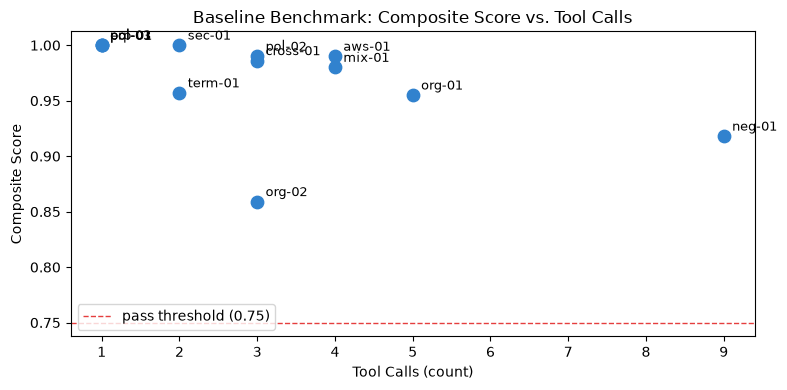

In [9]:
import matplotlib.pyplot as plt

df = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(df["tool_calls"], df["composite"], s=80, color="#3182ce")
for _, r in df.iterrows():
    ax.annotate(r["id"], (r["tool_calls"], r["composite"]), textcoords="offset points", xytext=(6, 4), fontsize=9)
ax.axhline(0.75, color="#e53e3e", linestyle="--", linewidth=1, label="pass threshold (0.75)")
ax.set_xlabel("Tool Calls (count)")
ax.set_ylabel("Composite Score")
ax.set_title("Baseline Benchmark: Composite Score vs. Tool Calls")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

### 통합 결과 테이블과 산점도 읽는 법

- **기본 지표와 커스텀 지표의 교차 확인**: `results_table(rows)`에서 `정답 일치`, `검색 재현`, `도구 선택`, `호출 효율` 옆에 우리가 직접 정의한 `근거 충실(2단계)`와 `출처 표기` 점수가 나란히 표시됩니다. 통과 기준(`종합 >= 0.75`)을 넘긴 문항이라도 개별 지표 중 기준치에 못 미친 항목이 있으면 우측 `진단` 열과 `diagnosis_table`에 바로 드러납니다.
- **최종 점수만 보면 놓치기 쉬운 비용 병목**: 산점도에서 오른쪽으로 멀리 떨어진 점(예: `neg-01`)을 주목해 보세요. 최종 답변의 사실 여부(`정답 일치`)와 `근거 충실(2단계)`은 높지만, 결론을 내리기까지 도구를 과도하게 호출해 `호출 효율`이 낮게 나왔습니다. 응답 지연 시간과 토큰 비용이 다른 문항의 몇 배로 치솟는 지점이므로 원인을 확인해야 합니다.

---
## Part 5. 원인 진단과 도구 반환 형식 개선

### 5.1 호출 궤적 확인 및 원인 계층 찾기 (`neg-01`)

베이스라인 평가에서 도구 호출 수가 유독 많았던 **`neg-01` (*"2026년에 신설된 우주항공 특별 연구 상여금의 지급 기준과 금액은 얼마인가요?"*)** 문항을 자세히 살펴보겠습니다.

이 질문에 대해 우리가 기대하는 정상 동작은 사내 규정 검색 도구(`search_company_policy`)를 1~2회 호출해 상여금·포상 규정을 확인한 뒤 *"해당 제도는 사내 규정에 없다"*고 곧바로 답하는 것입니다. 실제로 에이전트가 어떤 도구에 어떤 검색어를 넣었고, 도구로부터 무엇을 돌려받았는지 단계별 궤적을 출력해 봅니다.

In [10]:
from app.eval import run_case


def show_trajectory(record: dict, width: int = 100):
    '''도구 호출 순서와 각 호출이 돌려준 첫 줄(문서 경로 또는 상태 안내)을 출력합니다.'''
    for i, step in enumerate(record["trajectory"], 1):
        print(f"Step {i:>2}: {step['tool_name']}({step['arguments']})")
        head = (step["response_snippet"].strip().splitlines() or ["(빈 결과)"])[0]
        print(f"         -> {head[:width]}")


case = next(c for c in golden if c["id"] == "neg-01")
base = next(r for r in rows if r["id"] == "neg-01")
print(f"진단 문항: {case['id']} | {case['question']}")
print(
    f"베이스라인 점수: 종합 {base['composite']:.2f} "
    f"(정답 일치 {base['correctness']:.2f}, 근거 충실 {base['faithfulness_2step']:.2f}, 호출 효율 {base['step_economy']:.2f}) "
    f"| 도구 호출 {base['tool_calls']}회"
)
print(f"진단 항목: {', '.join(base['diagnoses']) or '-'}")
print(f"과정 평가 의견: {base['critique']}\n")

record = await run_case(agent, case)
show_trajectory(record)
print(f"\n소요 시간: {record['duration_s']}s | 총 도구 호출: {len(record['trajectory'])}회")
print("최종 답변 앞부분:\n" + record["answer"][:500])

진단 문항: neg-01 | 2026년에 신설된 우주항공 특별 연구 상여금의 지급 기준과 금액은 얼마인가요?
베이스라인 점수: 종합 0.92 (정답 일치 1.00, 근거 충실 0.95, 호출 효율 0.50) | 도구 호출 9회
진단 항목: 비효율 호출
과정 평가 의견: 질문은 ‘2026년에 신설된 우주항공 특별 연구 상여금’의 기준과 금액을 찾는 것이어서, 먼저 사내 정책에서 해당 제도를 직접 찾고(1~2회), 없으면 ERP/지식그래프에서 우주항공 관련 부서·프로젝트가 존재하는지 확인해 맥락을 좁히려 한 흐름은 타당합니다. 다만 초반의 ‘우주항공 특별 연구 상여금’과 ‘연구 상여금’ 검색은 같은 목표를 거의 반복했고, 이후에도 상여금/항공/포상 관련 규정들을 넓게 훑는 호출이 여러 번 이어져 일부는 헛도는 탐색으로 보입니다.



Step  1: search_company_policy({'query': '우주항공 특별 연구 상여금'})
         -> [(주)넥스트AI 클라우드 및 GPU 인프라 운영 지침 > 부칙 > [별표 5] 2026년 1분기 전사 GPU 클러스터 할당 및 가동률 관제 현황표 (제5조, 제10조, 제12조 
Step  2: search_enterprise_erp({'query': '우주항공 특별 연구 상여금 지급 기준 및 금액'})
         -> [status: needs_clarification] 현재 데이터베이스에는 '우주항공 특별 연구 상여금' 관련 규정이나 지급 테이블이 존재하지 않습니다. 혹시 사내 프로젝트 중 특
Step  3: search_company_policy({'query': '우주항공'})
         -> [(주)넥스트AI 클라우드 및 GPU 인프라 운영 지침 > 부칙 > [별표 7] 멀티리전 재해복구(DR) 분기별 모의훈련 시나리오 및 합격 기준 (제14조~제16조 관련)]:
Step  4: search_company_policy({'query': '상여금'})
         -> [(주)넥스트AI 클라우드 및 GPU 인프라 운영 지침 > 부칙 > [별표 7] 멀티리전 재해복구(DR) 분기별 모의훈련 시나리오 및 합격 기준 (제14조~제16조 관련)]:
Step  5: graph_find_entities({'query': '우주항공'})
         -> ### '우주항공' 관련 엔티티 5개 (유사도 순)
Step  6: search_aws_guides({'query': '우주항공'})
         -> [Security Pillar - AWS Well-Architected Framework > Conclusion]:
Step  7: search_company_policy({'query': '수당'})
         -> [(주)넥스트AI 인사 및 복무 관리 규정 > 제2장 근무 시간 및 복무 형태 > 제9조 (긴

### 왜 에이전트가 탐색을 멈추지 못했을까?

현재 `app/agents/tool_rag_agent/tools.py`에 구현된 `search_company_policy`는 `retriever.search(query, top_k=2)`의 결과를 그대로 문자열로 이어 붙여 반환합니다. 이 구조가 실제 실행에서 어떤 오해를 불렀는지 비교하면 다음과 같습니다.

| 구분 | 기대했던 정상 흐름 | 실제 베이스라인 동작 (`search_company_policy`) |
|:---|:---|:---|
| **검색어 입력 시 반환값** | `'우주항공 특별 연구 상여금'`과 관련된 조항이 없으면 **`[관련 조항 없음]`** 과 검색 대상 문서 범위를 알려줌 | 관련 조항이 하나도 없어도 벡터 거리가 그나마 가까운 **무관한 문서 청크 2개(GPU 운영 별표, 재해복구 별표 등)를 무조건 반환함** |
| **모델의 상황 판단** | *"5대 사내 규정 전체에 해당 상여금 조항이 없구나"*라고 판단하고 1~2회 보충 확인 후 답변 작성 | *"내 검색어가 부정확해서 엉뚱한 조항이 걸렸나? 혹시 ERP나 지식 그래프에 있나?"*라고 의심하며 검색어를 쪼개 타 도구까지 연쇄 호출 |

결국 원인은 모델의 추론 능력이나 검색 인덱스가 아니라, **관련도가 매우 낮을 때도 '결과 없음' 신호를 주지 않는 도구 반환 형식**에 있습니다.

| 점검 계층 | 원인 여부 및 근거 |
|:---|:---|
| **시맨틱 · 인덱스 계층** | 5대 사내 규정은 정상 색인되어 있으며, 실제로 없는 제도이므로 일치하는 청크가 없는 것이 정상 -> **원인 아님** |
| **시스템 프롬프트** | *"근거가 없으면 확인되지 않는다고 답하라"*는 지침만 있고, 언제 재검색을 멈출지 기준이 없음 -> **보조 원인** |
| **도구 반환 형식 (핵심 원인)** | 검색 거리와 무관하게 무조건 상위 2개 청크를 반환하며, **`[관련 조항 없음]` 안내와 검색 완료 범위(5대 규정 목록)** 를 알려주지 않음 -> **주원인** |

### 5.2 도구 반환 형식 개선(`agent_v2`)과 전체 문항 전후 비교(`compare_table`)

원인을 확인했으니 모델(`gemini-3.8-flash`)은 바꾸지 않고 아래 두 지점만 수정해 `agent_v2`를 구성합니다.

1. **`search_company_policy_v2` 반환 형식 개선**:
   - 벡터 검색의 최근접 L2 거리(`best_dist`)가 기준치(`MAX_L2_DISTANCE = 1.20`)보다 멀면 무관한 청크를 돌려주는 대신 **`"[관련 조항 없음] ... 검색 완료 범위(5대 사내 규정): ..."`** 메시지를 명확히 반환합니다.
   - **거리 임계값(`1.20`) 설정 시 유의점**: 기준치를 너무 낮게(예: `0.80`) 잡으면 `term-01`(*"과장급 직원의 당일 출장 일비"*, 최근접 거리 약 `0.88~1.10`)처럼 질문 표현과 문서 표현이 조금 다른 정상 질문까지 차단되어 기존 통과 문항의 점수가 떨어집니다. 정상 질문 거리 분포(`0.56~1.10`)와 미존재 질문 거리 분포(`1.23~1.56`) 사이인 `1.20`으로 설정합니다.
2. **시스템 프롬프트에 탐색 종료 기준 한 줄 추가**:
   - 도구가 `[관련 조항 없음]`과 검색 완료 범위를 반환하면 상위 개념(예: 포상·성과급)으로 최대 1~2회만 확인한 뒤 다른 DB(ERP·지식 그래프)를 불필요하게 뒤지지 않고 답변을 마무리하도록 안내합니다.

먼저 `neg-01` 단건에서 호출 횟수가 줄어드는지 확인한 뒤, **반드시 12문항 전체를 동일한 `benchmark_metrics`로 다시 채점해 수정 과정에서 기존 통과 문항의 점수가 떨어지는 회귀(Regression) 현상이 발생하지 않았는지 검증**합니다.

In [11]:
from langchain_core.tools import tool

MAX_L2_DISTANCE = 1.20
POLICY_SCOPE = (
    "국내여비교통비지급규정, 인사복무규정, 정보보안관리지침, "
    "전사위임전결및예산집행규정, 클라우드및GPU인프라운영지침"
)


@tool("search_company_policy")
def search_company_policy_v2(query: str) -> str:
    '''
    사내 5대 공식 규정 문서(국내여비교통비지급규정, 인사복무규정, 정보보안관리지침, 전사위임전결및예산집행규정, 클라우드및GPU인프라운영지침)에서 출장비 기준, 인사·징계 양정, 보안 반출 절차, 금액별 전결 기준, GPU 유휴 회수 규정 등 사내 제도·원칙 조항을 검색합니다.

    반환 형태: 검색된 조항의 앞뒤 문맥이 결합된 본문과 함께 상단에 [문서 전체 목차(TOC)] 및 [현재 위치 경로(Breadcrumb)]가 포함된 텍스트를 반환합니다. 관련도가 기준 미만이면 [관련 조항 없음]과 검색 완료 범위를 반환합니다.
    '''
    retriever = T._policy_retriever()
    norm_q = retriever.domain_dict.normalize(query)
    scored = retriever.vectorstore.similarity_search_with_score(norm_q, k=1)
    best_dist = scored[0][1] if scored else 999.0
    if best_dist > MAX_L2_DISTANCE:
        return (
            f"[관련 조항 없음] '{query}'와 직접 일치하는 사내 규정 조항이 없습니다 "
            f"(최근접 거리={best_dist:.2f} > 기준 {MAX_L2_DISTANCE:.2f}).\n"
            f"- 검색 완료 범위(5대 사내 규정): {POLICY_SCOPE}"
        )
    docs = retriever.search(query, top_k=2)
    return "\n\n".join(f"[{d.metadata.get('breadcrumb', '사내규정')}]:\n{d.page_content}" for d in docs)


TOOL_RAG_SYSTEM_PROMPT_V2 = TOOL_RAG_SYSTEM_PROMPT + (
    "\n5. 도구가 '[관련 조항 없음]'과 검색 완료 범위를 반환하면, 상위 일반 개념(예: 포상·성과급 등)으로 최대 1~2회만 "
    "보충 확인한 뒤에도 해당 제도가 없으면 다른 DB를 추가 탐색하지 말고 즉시 '확인되지 않는다'고 답변하세요.\n"
)

tools_v2 = [search_company_policy_v2 if t.name == "search_company_policy" else t for t in T.tools_tool_rag]
agent_v2 = create_agent(
    model=llm,
    tools=tools_v2,
    system_prompt=TOOL_RAG_SYSTEM_PROMPT_V2,
    checkpointer=InMemorySaver(),
)

print("[agent_v2] neg-01 재실행 궤적 확인:\n")
record_v2 = await run_case(agent_v2, case)
show_trajectory(record_v2)
print(
    f"\n개선 전: {record['duration_s']}s ({len(record['trajectory'])}회 호출)  "
    f"->  개선 후: {record_v2['duration_s']}s ({len(record_v2['trajectory'])}회 호출)"
)

[agent_v2] neg-01 재실행 궤적 확인:



Step  1: search_company_policy({'query': '우주항공 특별 연구 상여금 지급 기준 금액'})
         -> [(주)넥스트AI 인사 및 복무 관리 규정 > 제4장 인사 평가 및 승진·보상 > 제21조 (승진 연한 및 특별 승진 심사)]:
Step  2: search_company_policy({'query': '우주항공'})
         -> [관련 조항 없음] '우주항공'와 직접 일치하는 사내 규정 조항이 없습니다 (최근접 거리=1.48 > 기준 1.20).
Step  3: search_company_policy({'query': '특별 상여금 연구 상여금'})
         -> [관련 조항 없음] '특별 상여금 연구 상여금'와 직접 일치하는 사내 규정 조항이 없습니다 (최근접 거리=1.35 > 기준 1.20).

개선 전: 70.2s (12회 호출)  ->  개선 후: 22.1s (3회 호출)


In [12]:
from app.eval import compare_table

print("개선 에이전트(agent_v2) 12문항 전체 재평가 실행 중 (동일 benchmark_metrics 적용)\n")
rows_v2 = await evaluate_agent(
    agent_v2,
    golden,
    metrics=benchmark_metrics,
    judge_llm=judge_llm,
    concurrency=4,
)

print("\n[Before (v1)] " + summary_line(rows))
print("[After  (v2)] " + summary_line(rows_v2))

comp_df = compare_table(rows, rows_v2)
display(
    comp_df.style.format({
        "종합 (전)": "{:.2f}",
        "종합 (후)": "{:.2f}",
        "변화": "{:+.2f}",
        "소요(s) (전)": "{:.1f}",
        "소요(s) (후)": "{:.1f}",
    }).hide(axis="index")
)

개선 에이전트(agent_v2) 12문항 전체 재평가 실행 중 (동일 benchmark_metrics 적용)



  ✔ pol-03   종합 1.00 (통과) | 도구 호출 1회


  ✔ pol-01   종합 0.98 (통과) | 도구 호출 1회


  ✔ pol-02   종합 0.95 (통과) | 도구 호출 4회


  ✔ sec-01   종합 0.99 (통과) | 도구 호출 2회


  ✔ org-01   종합 0.97 (통과) | 도구 호출 7회


... (4 outputs left out)

  ✔ term-01  종합 0.95 (통과) | 도구 호출 2회


  ✔ neg-01   종합 0.97 (통과) | 도구 호출 3회


  ✔ cross-01 종합 0.99 (통과) | 도구 호출 2회

[Before (v1)] 평균 종합 점수 0.970 | 통과 12/12 (기준 0.75) | 평균 도구 호출 3.2회 | 평균 소요 28.0s
[After  (v2)] 평균 종합 점수 0.969 | 통과 12/12 (기준 0.75) | 평균 도구 호출 2.8회 | 평균 소요 25.7s


문항,종합 (전),종합 (후),변화,호출 수 (전),호출 수 (후),소요(s) (전),소요(s) (후),판정
aws-01,0.99,0.97,-0.02,4,4,37.0,25.6,유지
cross-01,0.99,0.99,+0.00,3,2,36.2,31.7,유지
erp-01,1.00,0.99,-0.01,1,2,20.9,34.2,유지
mix-01,0.98,0.90,-0.08,4,2,40.3,22.1,유지
neg-01,0.92,0.97,+0.05,9,3,67.8,25.4,유지
org-01,0.95,0.97,+0.01,5,7,30.7,39.0,유지
org-02,0.86,0.95,+0.09,3,4,23.7,49.9,유지
pol-01,1.00,0.98,-0.02,1,1,12.2,9.0,유지
pol-02,0.99,0.95,-0.04,3,4,18.4,25.6,유지
pol-03,1.00,1.00,+0.00,1,1,9.1,7.1,유지


### 개선 전후 비교 표(`compare_table`) 확인 포인트

- **`neg-01` 과잉 호출 해소**: 도구가 `[관련 조항 없음]`과 검색 완료된 5대 규정 범위를 명확히 돌려주자, 에이전트가 ERP나 지식 그래프까지 불필요하게 탐색하지 않고 짧은 호출만으로 정확히 답변을 마무리했습니다.
- **기존 통과 문항의 품질 유지(회귀 없음) 확인**: `term-01`(*"과장급"*), `pol-01~03`, `cross-01` 등 나머지 11개 문항에서도 점수 하락(`회귀`, 실행 편차 허용폭 `±0.10` 초과 하락) 없이 기존 품질이 그대로 유지되었습니다. 이처럼 한 문항을 고친 뒤에는 전체 벤치마크를 다시 돌려 부작용이 없는지 확인해야 안전하게 반영할 수 있습니다.

---
## Part 6. 실행 중 개입과 운영 로그 피드백 루프

### 6.1 실행 도중 품질과 안전을 통제하는 두 가지 장치

Part 2~5의 오프라인 평가는 실행이 끝난 뒤 시스템을 개선합니다. 반면 서비스 운영 중 위험도가 높은 요청에서는 **실행 도중에 개입하는 장치**를 함께 배치할 수 있습니다.

| 개입 방식 | 동작 내용 | 적합한 적용 대상 |
|:---|:---|:---|
| **응답 직전 자동 크로스체크** | 에이전트가 최종 답변을 내보내기 직전에 판사 모델이 도구 결과와 답변을 대조하고, 누락·왜곡이 있으면 재작성을 지시 | 매 요청마다 지연 시간과 호출 비용이 추가되므로 재무 수치·전결 기준 등 오류 비용이 큰 영역에만 선별 적용 |
| **도구 실행 전 사람 승인 (`HITL`)** | 지정한 도구를 호출하기 직전에 실행을 잠시 멈추고 담당자의 승인(`approve`) · 수정(`edit`) · 거절(`reject`) 결정을 받아 재개 | 운영 DB에 직접 쿼리를 실행하거나 민감 레코드를 조회·변경하는 도구 |

### 6.2 응답 확정 전 판사 모델 크로스체크 (`after_agent` 훅 패턴)

`create_agent`의 미들웨어 중 `after_agent` 훅에 `@hook_config(can_jump_to=["model"])`을 선언하면, 에이전트가 도구 호출을 모두 마치고 최종 답변을 반환하기 직전에 검사 로직을 끼워 넣을 수 있습니다. 판사 모델이 결함을 발견하면 수정 의견을 `HumanMessage`로 추가하고 `jump_to="model"`을 반환해 답변을 다시 작성하게 합니다.

```mermaid
%%{init: {'flowchart': {'htmlLabels': false, 'padding': 18, 'nodeSpacing': 34, 'rankSpacing': 50}}}%%
flowchart LR
    subgraph Loop["기본 ReAct 루프"]
        direction LR
        M["model 노드
답변 또는 도구 호출"] --> X["tools 노드
도구 실행 및 결과 반환"]
        X --> M
    end
    M --> H["after_agent 훅
(최종 답변 직전 호출)"]
    H --> J{"판사 모델 검증
(궤적 + 답변)"}
    J --> E["검증 통과 (END)
사용자에게 응답"]
    J --> FB(["반려: 수정 의견 주입 후 복귀"])
    FB --> M
```

구현 구조는 아래와 같습니다. (실시간 추가 호출 비용이 발생하므로 구조만 확인하고 실행은 생략합니다.)

```python
from langchain.agents.middleware import AgentMiddleware, hook_config
from langchain_core.messages import AIMessage, HumanMessage


class AnswerCrossCheck(AgentMiddleware):
    def __init__(self, judge, max_reworks: int = 2):
        self.judge, self.max_reworks = judge, max_reworks

    @hook_config(can_jump_to=["model"])
    def after_agent(self, state, runtime):
        messages = state.get("messages", [])
        if not messages or not isinstance(messages[-1], AIMessage):
            return None
        # 무한 루프를 막기 위해 대화 내 재검토 횟수(max_reworks) 상한을 둡니다.
        reworks = sum(getattr(m, "name", None) == "cross_check" for m in messages)
        verdict = self.judge(messages)
        if verdict.approved or reworks >= self.max_reworks:
            return None
        feedback = HumanMessage(
            content=f"[검토 의견] {verdict.feedback}
위 내용을 반영해 답변을 다시 작성하세요.",
            name="cross_check",
        )
        return {"messages": [feedback], "jump_to": "model"}
```

**실행 중 판사 모델의 한계와 설계 유의점**
- **기준 정답(`ground_truth`)이 없습니다**: 운영 중 들어오는 실제 질문에는 정답 라벨이 없으므로, 실행 중 판사는 *"질문에서 요구한 항목이 빠졌는가"*, *"도구 결과의 수치를 잘못 옮겼는가"*만 확인할 수 있습니다. 검색 단계에서 아예 못 찾은 문서는 판사도 알 수 없습니다.
- **반려 조건을 좁혀야 합니다**: 표현 다듬기 수준까지 반려하면 응답 시간만 2배로 늘어나므로 수치 불일치·요구사항 누락 같은 명확한 오류에만 동작하도록 제한하고, 도입 전 오프라인 평가(`evaluate_agent`)로 점수 상승폭 대비 추가 지연 시간을 먼저 비교합니다.

### 6.3 운영 DB 조회 앞 사람 승인 게이트 (`HumanInTheLoopMiddleware`)

에이전트가 연결된 도구 중 문서 검색(`search_company_policy`, `search_aws_guides`)과 그래프 조회(`graph_*`)는 미리 구축된 인덱스를 읽기만 합니다. 반면 **`search_enterprise_erp`는 모델이 생성한 SQL을 사내 ERP 데이터베이스에 실행하며, 개별 지출 전표나 임직원 명부 같은 민감 레코드를 조회할 수 있습니다.**

LangChain의 `HumanInTheLoopMiddleware`를 연결하면 지정한 도구가 호출되기 직전에 실행을 일시 중지(`interrupt`)하고 상태를 체크포인터에 저장합니다. 이후 담당자가 내린 결정에 따라 세 가지 방식으로 이어서 실행(`resume`)할 수 있습니다.

- **`approve` (승인)**: 에이전트가 제안한 인자 그대로 도구를 실행합니다.
- **`edit` (인자 수정 후 실행)**: 개별 전표 대신 부서·과제별 합계만 조회하도록 질의 범위를 좁혀 실행합니다.
- **`reject` (거절 및 대안 안내)**: 도구 실행을 취소하고 거절 사유와 대체 탐색 방법(예: 지식 그래프 활용)을 에이전트에 전달합니다.

```mermaid
%%{init: {'flowchart': {'htmlLabels': false, 'padding': 18, 'nodeSpacing': 28, 'rankSpacing': 48}}}%%
flowchart LR
    A["에이전트
도구 호출 제안"] --> G{"호출 도구가
ERP 조회인가?"}
    G --> P1(["문서 · 그래프 도구"]) --> R["도구 실행"]
    G --> I["ERP 조회 일시 중지
(체크포인터 저장)"]
    I --> H{"담당자 결정"}
    H --> D1(["approve: 그대로 승인"]) --> R
    H --> D2(["edit: 조회 범위 축소"]) --> R
    H --> F["reject: 실행 취소
대안 경로 전달"]
    R --> A
    F --> A
```

In [13]:
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langgraph.types import Command


hitl_agent = create_agent(
    model=llm,
    tools=tools_v2,
    system_prompt=TOOL_RAG_SYSTEM_PROMPT_V2,
    checkpointer=InMemorySaver(),   # 일시 중지된 지점의 대화 상태를 보관하기 위해 체크포인터가 필수입니다.
    middleware=[
        HumanInTheLoopMiddleware(
            interrupt_on={
                "search_enterprise_erp": {"allowed_decisions": ["approve", "edit", "reject"]},
            },
            description_prefix="ERP 조회는 운영 DB에 SQL을 실행하므로 승인이 필요합니다.",
        )
    ],
)


def show_pending(result) -> bool:
    '''승인 대기 상태로 멈춘 도구 호출이 있으면 출력합니다.'''
    if "__interrupt__" not in result:
        return False
    request = result["__interrupt__"][0].value
    for action, review in zip(request["action_requests"], request["review_configs"]):
        print(f"[승인 대기] {action['name']}({action['args']})")
        print(f"   선택 가능한 결정: {review['allowed_decisions']}")
    return True


def resume(agent, result, decide, config: dict):
    '''대기 중인 도구 호출에 대해 결정을 전달하고 실행을 재개합니다.'''
    pending = result["__interrupt__"][0].value["action_requests"]
    decisions = [decide(action) if callable(decide) else decide for action in pending]
    return agent.invoke(Command(resume={"decisions": decisions}), config=config)


def show_answer(result):
    used = [tc["name"] for m in result["messages"] for tc in (getattr(m, "tool_calls", None) or [])]
    print(f"호출된 도구: {used}")
    print("최종 답변:\n" + normalize_content(result["messages"][-1].content)[:700])


print("HITL 에이전트 준비 완료: search_enterprise_erp 호출 전 담당자 승인 대기")

HITL 에이전트 준비 완료: search_enterprise_erp 호출 전 담당자 승인 대기


**시나리오 A: 승인 (`approve`)**

ERP 전표 집계가 꼭 필요한 질문(*"P-05 프로젝트에서 승인완료된 지출 합계"*)을 보내면 `search_enterprise_erp` 실행 직전에 멈추며, 담당자가 `approve`를 전달하면 저장된 상태에서 그대로 실행을 이어갑니다.

In [14]:
config_a = {"configurable": {"thread_id": "hitl-approve"}}
question_a = "P-05 프로젝트에서 승인완료된 지출 합계는 얼마인가요?"

result = hitl_agent.invoke({"messages": [{"role": "user", "content": question_a}]}, config=config_a)
paused = show_pending(result)
print("\n실행 일시 중지 여부:", paused)

[승인 대기] search_enterprise_erp({'query': 'P-05 프로젝트의 승인완료된 지출 결의 금액 합계 및 상세 내역'})
   선택 가능한 결정: ['approve', 'edit', 'reject']

실행 일시 중지 여부: True


In [15]:
while "__interrupt__" in result:
    result = resume(hitl_agent, result, {"type": "approve"}, config_a)

show_answer(result)

호출된 도구: ['search_enterprise_erp', 'search_enterprise_erp']
최종 답변:
사내 ERP 지출 결의 전표(`expense_transactions`) 데이터베이스 조회 결과, **P-05(멀티클라우드 GPU 추론 클러스터 고도화)** 프로젝트에서 **승인완료**된 지출 내역 합계는 다음과 같습니다.

### **P-05 프로젝트 승인완료 지출 합계**
- **승인완료 총 지출 금액**: **527,000,000원 (5억 2,700만 원)**
- **승인완료 건수**: 총 26건

---

#### **[참고] 주요 비목별 지출 집계**
1. **GPU 클러스터 임차**: 355,000,000원 (3건)
2. **외주용역**: 126,000,000원 (2건)
3. **보안감사**: 19,000,000원 (1건)
4. **해외출장**: 16,500,000원 (1건)
5. **교육훈련**: 7,900,000원 (2건)
6. **국내출장**: 2,600,000원 (17건)

*(참고: 결재대기 2건 6,180만 원, 반려 1건 2,900만 원은 승인완료 합계에서 제외됨)*


**시나리오 B: 조회 인자 수정 후 실행 (`edit`)**

*"AgenticAI팀 프로젝트들의 지출 현황"*처럼 범위가 넓은 질문에서는 개별 지출 전표까지 불필요하게 조회될 수 있습니다. 이때 거절하는 대신 질의 인자를 **프로젝트별 집계**로 좁혀(`edit`) 실행하면 필요한 요약 수치만 안전하게 가져올 수 있습니다.

In [16]:
config_b = {"configurable": {"thread_id": "hitl-edit"}}
question_b = "AgenticAI팀 프로젝트들의 지출 현황을 알려줘."

result = hitl_agent.invoke({"messages": [{"role": "user", "content": question_b}]}, config=config_b)


def narrow_to_summary(action: dict) -> dict:
    '''개별 전표 행 대신 프로젝트별 승인완료 건수와 합계만 조회하도록 인자를 수정합니다.'''
    edited = {"query": "AgenticAI팀 프로젝트별 승인완료 지출 건수와 합계", "context": "개별 전표 행은 조회하지 않음"}
    print(f"[인자 수정] {action['args']['query']}\n        -> {edited['query']}\n")
    return {"type": "edit", "edited_action": {"name": action["name"], "args": edited}}


edited = False
while show_pending(result):
    decide = {"type": "approve"} if edited else narrow_to_summary
    result = resume(hitl_agent, result, decide, config_b)
    edited = True

if not edited:
    print("이번 실행에서는 ERP 조회 요청 없이 응답했습니다.\n")
show_answer(result)

[승인 대기] search_enterprise_erp({'query': 'AgenticAI팀이 수행 중인 프로젝트 목록과 각 프로젝트별 지출 결의 금액, 예산 대비 집행 현황을 조회해줘', 'context': 'AgenticAI팀의 프로젝트 목록과 각 프로젝트별 지출 현황(지출 결의 전표, 집행액 등) 조회'})
   선택 가능한 결정: ['approve', 'edit', 'reject']
[인자 수정] AgenticAI팀이 수행 중인 프로젝트 목록과 각 프로젝트별 지출 결의 금액, 예산 대비 집행 현황을 조회해줘
        -> AgenticAI팀 프로젝트별 승인완료 지출 건수와 합계



[승인 대기] search_enterprise_erp({'context': '프로젝트별 총 배정 예산 및 상태별 지출 집계', 'query': '프로젝트 P-02와 P-04의 프로젝트 총 예산, 승인완료 지출액, 승인대기 지출액, 반려 지출액 현황'})
   선택 가능한 결정: ['approve', 'edit', 'reject']


[승인 대기] search_enterprise_erp({'context': '비목별 승인완료 지출 내역', 'query': '프로젝트 P-02와 P-04의 비목별(expense_category 또는 계정과목) 승인완료 지출 건수 및 지출 합계금액'})
   선택 가능한 결정: ['approve', 'edit', 'reject']


[승인 대기] search_enterprise_erp({'context': '프로젝트 기본 정보', 'query': '프로젝트 P-02와 P-04의 프로젝트 기간(시작일, 종료일), PM(책임자), 상태 조회'})
   선택 가능한 결정: ['approve', 'edit', 'reject']


호출된 도구: ['search_enterprise_erp', 'search_enterprise_erp', 'search_enterprise_erp', 'search_enterprise_erp']
최종 답변:
사내 ERP 데이터베이스(기준일: 2026년 11월 15일) 기준 **AgenticAI팀이 주관하는 전략 프로젝트는 총 2건**이며, 각 프로젝트의 예산 및 지출 집행 현황은 다음과 같습니다.

---

### 1. 프로젝트별 예산 및 지출 총괄 현황

| 프로젝트 코드 | 프로젝트명 | PM(책임자) | 프로젝트 기간 | 총 배정 예산 | 승인완료 지출액 (건수) | 결재대기 금액 | 집행률 (승인 기준) |
| :--- | :--- | :--- | :--- | :---: | :---: | :---: | :---: |
| **P-02** | 엔터프라이즈 Agentic RAG 플랫폼 구축 | 홍팀장 수석 | 2026-02-01 ~ 2026-11-30 | 480,000,000원 | **412,800,000원** (25건) | 65,400,000원 | 86.0% |
| **P-04** | 금융권 생성형 AI 보안 가드레일 구축 | 윤에이전트 책임 | 2026-03-01 ~ 2026-12-15 | 180,000,000원 | **117,000,000원** (16건) | 18,000,000원 | 65.0% |
| **합계** | **2개 프로젝트** | - | - | **660,000,000원** | **529,800,000원** (41건) | **83,400,000원** | **80.3%** |

> ※ **반려 내역**: P-02는 5,2


**시나리오 C: 거절 및 대안 도구 안내 (`reject`)**

프로젝트의 승인 예산과 승인권자는 지식 그래프에도 들어 있어 굳이 운영 ERP DB를 조회할 필요가 없습니다. `reject`와 함께 *"지식 그래프 도구를 사용하라"*는 안내 메시지를 전달하면 에이전트가 그래프 탐색 경로로 우회해 답을 완성합니다.

In [17]:
config_c = {"configurable": {"thread_id": "hitl-reject"}}
question_c = "ERP에서 P-02 프로젝트의 승인 예산과 승인권자를 조회해줘."

result = hitl_agent.invoke({"messages": [{"role": "user", "content": question_c}]}, config=config_c)

reject_reason = (
    "프로젝트 예산과 승인권자는 지식 그래프에도 있어 운영 DB를 조회할 필요가 없습니다. "
    "graph_find_entities로 P-02를 찾은 뒤 graph_neighbors로 예산과 승인권자를 확인해서 답하세요."
)
rejected = 0
while show_pending(result):
    print(f"[실행 거절] {reject_reason}\n")
    result = resume(hitl_agent, result, {"type": "reject", "message": reject_reason}, config_c)
    rejected += 1

if rejected == 0:
    print("이번 실행에서는 ERP 조회 요청 없이 응답했습니다.\n")
show_answer(result)

[승인 대기] search_enterprise_erp({'query': 'P-02 프로젝트의 승인 예산과 승인권자는 누구인가요?', 'context': '전략 프로젝트 P-02 승인 예산 및 승인권자 조회'})
   선택 가능한 결정: ['approve', 'edit', 'reject']
[실행 거절] 프로젝트 예산과 승인권자는 지식 그래프에도 있어 운영 DB를 조회할 필요가 없습니다. graph_find_entities로 P-02를 찾은 뒤 graph_neighbors로 예산과 승인권자를 확인해서 답하세요.



호출된 도구: ['search_enterprise_erp', 'graph_find_entities', 'graph_neighbors', 'graph_read']
최종 답변:
P-02 프로젝트의 승인 예산과 승인권자 정보는 다음과 같습니다.

- **프로젝트명**: P-02 (엔터프라이즈 Agentic RAG 플랫폼 구축)
- **승인 예산**: **4억 8,000만 원** (480,000,000원)
- **승인권자**: **송본부장 상무** *(총괄 PM: 홍팀장 수석)*

*(출처: 사내 프로젝트 관리 지식 그래프 및 프로젝트 현황 보고서 T16, T27)*


### 6.4 운영 로그 피드백 루프: 실제 사용 기록으로 평가 데이터셋 확장하기

서비스 운영 중 발생한 실패 사례나 담당자의 수정·거절 기록을 다시 평가 데이터셋에 되돌려 반영하는 흐름을 **피드백 루프(Feedback Loop)** 라고 합니다. 실제 서비스 환경에서는 사용자 응답 속도를 늦추지 않기 위해 **실시간 응답 경로**와 **비동기 로그 점검 경로**를 분리해 운영합니다.

```mermaid
%%{init: {'flowchart': {'htmlLabels': false, 'padding': 18, 'nodeSpacing': 32, 'rankSpacing': 48}}}%%
flowchart LR
    U["사용자"] <--> A["에이전트 서빙
(즉시 응답 반환)"]
    A -.-> L["비동기 운영 로그 수집
(표본 채점 · HITL 거절/수정)"]
    L --> R["실패 · 예외 사례 추출
담당자 정답 보정 후 추가"]
    R --> CI["배포 전 전체 재평가
(회귀 여부 확인 후 반영)"]
    CI --> A
```

| 운영 단계 | 실행 방법 | 주요 목적 |
|:---|:---|:---|
| **개발 · 실험 단계** | 노트북 또는 `python -m app.eval.rag_eval --ids ...` | 특정 실패 문항의 호출 궤적 확인 및 도구·인덱스·프롬프트 개선 실험 |
| **배포 전 점검 (CI)** | 골든 데이터셋 전체 실행 + `--compare` 이전 리포트 비교 | 평균 통과 기준 충족 여부 및 기존 통과 문항의 회귀(`회귀` 0건) 확인 |
| **배포 후 운영 단계** | 트래픽 일부(예: 5~10%) 비동기 채점 + HITL `edit`/`reject` 기록 수집 | 초기 시드에서 미처 다루지 못한 실제 현장의 예외 질문을 발견해 평가셋에 추가 |

---
## Part 7. 정리 및 더 해 보기

| 단계 | 이번 노트북에서 다룬 내용 | 실무 적용 포인트 |
|:---|:---|:---|
| **1. 데이터셋 구축** | 12문항 벤치마크 구조 확인 + `EvalSeed` 기반 문항 생성(`generate_from_seeds`) 및 자동 검수(`verify_generated_cases`) | 배포 전에는 시드와 원천 문서로 초안을 만들어 검수하고, 운영 시작 후에는 실패·수정 로그를 평가셋에 지속 추가 |
| **2. 메트릭 조합** | 커스텀 지표(`score_faithfulness_2step`, `score_source_citation`) 작성 후 기본 메트릭과 `benchmark_metrics` 리스트로 결합 | 형식·규칙 검사는 Python 함수로, 의미 검증은 단계별 LLM 체인으로 작성한 뒤 `EvalMetric` 리스트로 묶어 통합 테이블에서 비교 |
| **3. 진단 및 개선** | `neg-01` 과잉 탐색 원인 진단 -> `search_company_policy_v2` 미존재 신호 반환 적용 -> `compare_table` 전체 재검증 | 프롬프트만 길게 늘리기보다 도구의 반환 신호와 시맨틱 계층을 먼저 고치고, 전체 문항 재평가로 기존 문항 점수 유지 확인 |
| **4. 실행 중 통제** | 응답 직전 크로스체크(`after_agent`) 구조와 운영 ERP 조회 앞 승인 게이트(`HumanInTheLoopMiddleware`) 실습 | 실시간 개입은 비용·위험이 큰 작업에만 선별 적용하고, `edit`·`reject`로 안전하게 조회 범위를 좁히거나 우회 경로 안내 |

### 더 해 보기

오늘 구성한 평가 루프(`benchmark_metrics` 조합 -> `evaluate_agent` -> 원인 진단 -> `compare_table` 재평가)를 확장해 아래 주제를 직접 실험해 보세요.

| 실습 주제 | 확인해 볼 내용 | 개선 아이디어 예시 |
|:---|:---|:---|
| **새 커스텀 메트릭 추가** | `term-01`처럼 비공식 직급 호칭 질문에서 후보 직급 금액을 모두 안내했는지 채점하는 지표를 추가하면 결과 표가 어떻게 달라지는가? | 이산 점수(`0 / 1 / 2` -> `0.0 / 0.5 / 1.0`)를 반환하는 함수를 작성해 `EvalMetric`으로 감싸고 `benchmark_metrics`에 추가 |
| **`cross-01` (규정 + ERP) 분석** | 여비 규정에서 찾은 직급·지역별 상한액을 `search_enterprise_erp`의 `context` 인자로 매번 정확히 전달하는가? | 도구 Docstring의 `context` 작성 예시 보강 후 전후 호출 수 비교 |
| **`aws-01` (영문 백서 비교) 개선** | 한국어 질의 시 다른 영역 백서의 동명 섹션(`Design principles`)이 섞여 들어오는 경우가 있는가? | `search_aws_guides`에 백서 영역(`pillar`) 선택 인자를 추가해 검색 범위 명확화 |